In [1]:
# ============================================================
# STEP 1: INSTALL REQUIRED LIBRARIES
# ============================================================

# Run this cell only if the libraries are not already installed.

!pip install pandas numpy matplotlib seaborn scikit-learn shap


   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   -------------------- ------------------- 1/2 [shap]
   ---------------------------------------- 2/2 [shap]



In [57]:
# ============================================================
# STEP 2: IMPORT REQUIRED LIBRARIES
# ============================================================

# Data handling
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Explainable AI
import shap

# Ignore unnecessary warning messages
import warnings
warnings.filterwarnings("ignore")


# Machine Learning - Data Splitting
from sklearn.model_selection import train_test_split


# Machine Learning - Preprocessing
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer


# Machine Learning Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor

from sklearn.ensemble import (
    RandomForestRegressor,
    GradientBoostingRegressor,
    StackingRegressor
)

from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR


# Evaluation Metrics
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [3]:
# ============================================================
# STEP 3: LOAD DATASET
# ============================================================

# Read the food wastage CSV file
df = pd.read_csv("food_wastage_data.csv")


# Display the size of the dataset
print("Dataset Shape:", df.shape)


# Display all column names
print("\nColumn Names:")
print(df.columns.tolist())


# Display first five records
print("\nFirst Five Records:")
display(df.head())

Dataset Shape: (1782, 11)

Column Names:
['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']

First Five Records:


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
0,Meat,310,Corporate,450,Refrigerated,Regular,All Seasons,Buffet,Urban,Low,25
1,Meat,400,Birthday,500,Room Temperature,Regular,Winter,Buffet,Suburban,High,40
2,Vegetables,302,Birthday,371,Refrigerated,Regular,Summer,Buffet,Suburban,Low,27
3,Meat,491,Birthday,497,Refrigerated,Regular,All Seasons,Finger Food,Rural,High,32
4,Meat,300,Corporate,400,Refrigerated,Regular,Winter,Finger Food,Urban,Moderate,25


In [4]:
# ============================================================
# STEP 4: UNDERSTAND THE DATASET
# ============================================================

# Display information about columns,
# data types and non-null values

print(df.info())


# Display statistical information
print("\nStatistical Summary:")
display(df.describe(include="all"))

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1782 entries, 0 to 1781
Data columns (total 11 columns):
 #   Column                 Non-Null Count  Dtype 
---  ------                 --------------  ----- 
 0   Type of Food           1782 non-null   object
 1   Number of Guests       1782 non-null   int64 
 2   Event Type             1782 non-null   object
 3   Quantity of Food       1782 non-null   int64 
 4   Storage Conditions     1782 non-null   object
 5   Purchase History       1782 non-null   object
 6   Seasonality            1782 non-null   object
 7   Preparation Method     1782 non-null   object
 8   Geographical Location  1782 non-null   object
 9   Pricing                1782 non-null   object
 10  Wastage Food Amount    1782 non-null   int64 
dtypes: int64(3), object(8)
memory usage: 153.3+ KB
None

Statistical Summary:


,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Wastage Food Amount
count,1782,1782.000000,1782,1782.000000,1782,1782,1782,1782,1782,1782,1782.000000
unique,5,NaN,4,NaN,2,2,3,3,3,3,NaN
top,Meat,NaN,Corporate,NaN,Room Temperature,Regular,Winter,Sit-down Dinner,Suburban,High,NaN
freq,437,NaN,515,NaN,1157,1576,632,781,821,674,NaN
mean,NaN,317.804714,NaN,411.125701,NaN,NaN,NaN,NaN,NaN,NaN,28.536476
std,NaN,67.829658,NaN,65.204674,NaN,NaN,NaN,NaN,NaN,NaN,10.461317
min,NaN,207.000000,NaN,280.000000,NaN,NaN,NaN,NaN,NaN,NaN,10.000000
25%,NaN,267.000000,NaN,350.000000,NaN,NaN,NaN,NaN,NaN,NaN,20.000000
50%,NaN,302.000000,NaN,400.000000,NaN,NaN,NaN,NaN,NaN,NaN,26.500000
75%,NaN,350.000000,NaN,480.000000,NaN,NaN,NaN,NaN,NaN,NaN,35.000000


In [5]:
# ============================================================
# STEP 5: DATA CLEANING
# ============================================================

# Remove unwanted spaces from column names
df.columns = df.columns.str.strip()


# Display cleaned column names
print("Cleaned Column Names:")
print(df.columns.tolist())

Cleaned Column Names:
['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Wastage Food Amount']


In [6]:
# ============================================================
# STEP 6: MISSING VALUE ANALYSIS
# ============================================================

# Count missing values in every column
missing_values = df.isnull().sum()

print("Missing Values in Each Column:")
print(missing_values)


# Calculate percentage of missing values
missing_percentage = (
    df.isnull().sum() / len(df)
) * 100

print("\nMissing Value Percentage:")
print(missing_percentage)

Missing Values in Each Column:
Type of Food             0
Number of Guests         0
Event Type               0
Quantity of Food         0
Storage Conditions       0
Purchase History         0
Seasonality              0
Preparation Method       0
Geographical Location    0
Pricing                  0
Wastage Food Amount      0
dtype: int64

Missing Value Percentage:
Type of Food             0.0
Number of Guests         0.0
Event Type               0.0
Quantity of Food         0.0
Storage Conditions       0.0
Purchase History         0.0
Seasonality              0.0
Preparation Method       0.0
Geographical Location    0.0
Pricing                  0.0
Wastage Food Amount      0.0
dtype: float64


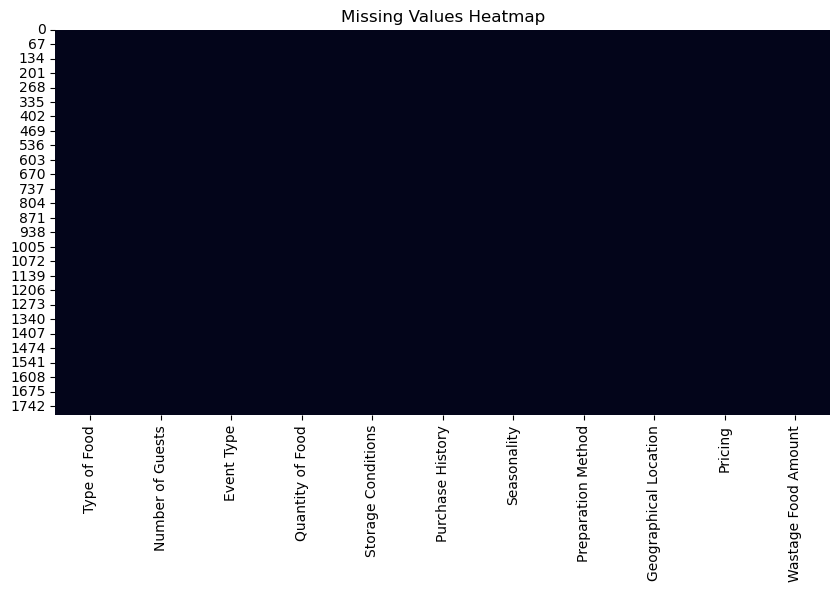

In [7]:
# ============================================================
# MISSING VALUE VISUALIZATION
# ============================================================

plt.figure(figsize=(10, 5))

sns.heatmap(
    df.isnull(),
    cbar=False
)

plt.title("Missing Values Heatmap")

plt.show()

In [8]:
# ============================================================
# STEP 7: DUPLICATE CHECK
# ============================================================

# Count duplicate rows
duplicate_count = df.duplicated().sum()

print("Number of Duplicate Rows:",
      duplicate_count)


# Remove duplicate rows
df = df.drop_duplicates()


# Display new dataset shape
print(
    "Dataset Shape After Removing Duplicates:",
    df.shape
)


Number of Duplicate Rows: 164
Dataset Shape After Removing Duplicates: (1618, 11)


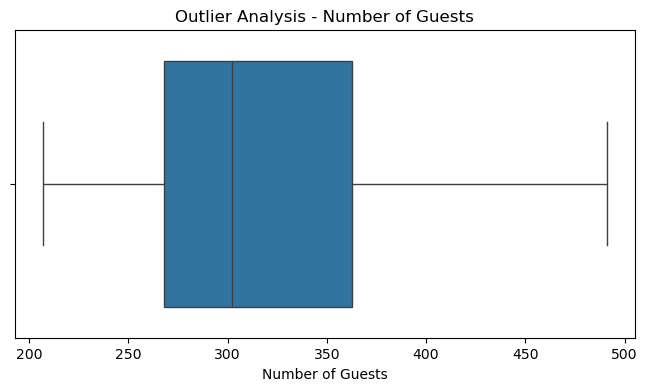

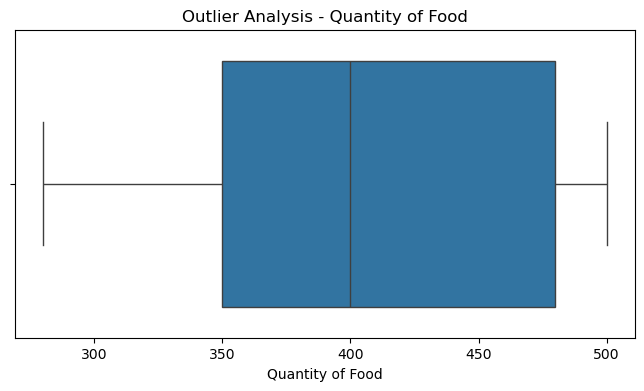

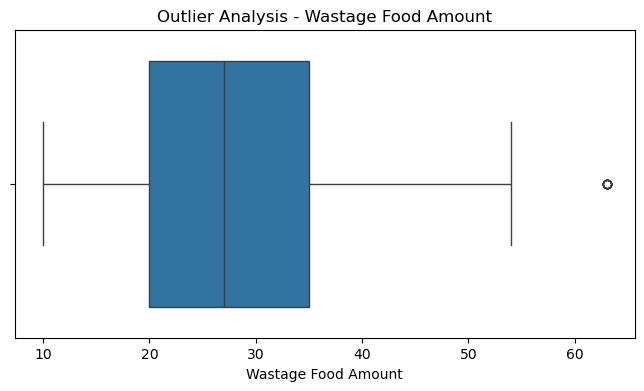

In [9]:
# ============================================================
# STEP 8: OUTLIER ANALYSIS
# ============================================================

# Select important numerical columns
numeric_columns = [
    "Number of Guests",
    "Quantity of Food",
    "Wastage Food Amount"
]


# Create boxplots for each numerical feature
for column in numeric_columns:

    plt.figure(figsize=(8, 4))

    sns.boxplot(
        x=df[column]
    )

    plt.title(
        f"Outlier Analysis - {column}"
    )

    plt.show()

In [10]:
# ============================================================
# IQR OUTLIER DETECTION
# ============================================================

for column in numeric_columns:

    # First quartile
    Q1 = df[column].quantile(0.25)

    # Third quartile
    Q3 = df[column].quantile(0.75)

    # Interquartile range
    IQR = Q3 - Q1

    # Lower boundary
    lower_limit = Q1 - 1.5 * IQR

    # Upper boundary
    upper_limit = Q3 + 1.5 * IQR

    # Find outliers
    outliers = df[
        (df[column] < lower_limit) |
        (df[column] > upper_limit)
    ]

    print(
        column,
        "→ Number of Outliers:",
        len(outliers)
    )

Number of Guests → Number of Outliers: 0
Quantity of Food → Number of Outliers: 0
Wastage Food Amount → Number of Outliers: 9


In [11]:
# ============================================================
# STEP 9: FEATURE ENGINEERING
# ============================================================

# ------------------------------------------------------------
# Feature 1: Food prepared per guest
# ------------------------------------------------------------

df["Food_Per_Guest"] = (
    df["Quantity of Food"] /
    df["Number of Guests"].replace(0, np.nan)
)


# ------------------------------------------------------------
# Feature 2: Categorize number of guests
# ------------------------------------------------------------

df["Guest_Category"] = pd.cut(

    df["Number of Guests"],

    bins=[
        0,
        150,
        300,
        450,
        np.inf
    ],

    labels=[
        "Small",
        "Medium",
        "Large",
        "Very Large"
    ]
)


# ------------------------------------------------------------
# Feature 3: Categorize quantity of food
# ------------------------------------------------------------

df["Quantity_Category"] = pd.qcut(

    df["Quantity of Food"],

    q=4,

    labels=[
        "Low",
        "Medium",
        "High",
        "Very High"
    ],

    duplicates="drop"
)


# Display newly created features
print("New Features Created:")

display(
    df[
        [
            "Food_Per_Guest",
            "Guest_Category",
            "Quantity_Category"
        ]
    ].head()
)

New Features Created:


,Food_Per_Guest,Guest_Category,Quantity_Category
0,1.451613,Large,High
1,1.250000,Large,Very High
2,1.228477,Large,Medium
3,1.012220,Very Large,Very High
4,1.333333,Medium,Medium


In [12]:
# ============================================================
# STEP 10: CONTEXT FEATURE FUSION
# ============================================================

# Features representing demand/context
features = [

    # Food information
    "Type of Food",

    # Guest information
    "Number of Guests",

    # Event information
    "Event Type",

    # Quantity / demand information
    "Quantity of Food",

    # Storage information
    "Storage Conditions",

    # Inventory / purchasing information
    "Purchase History",

    # Seasonal information
    "Seasonality",

    # Preparation information
    "Preparation Method",

    # Geographic information
    "Geographical Location",

    # Pricing information
    "Pricing",

    # Engineered features
    "Food_Per_Guest",
    "Guest_Category",
    "Quantity_Category"
]


# Target variable
# This is what the ML model will predict.
target = "Wastage Food Amount"


# Create input data
X = df[features]


# Create target data
y = df[target]


print("Input Features:")
print(X.columns.tolist())

print("\nTarget Variable:")
print(target)

Input Features:
['Type of Food', 'Number of Guests', 'Event Type', 'Quantity of Food', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Food_Per_Guest', 'Guest_Category', 'Quantity_Category']

Target Variable:
Wastage Food Amount


In [13]:
# ============================================================
# STEP 11: IDENTIFY FEATURE TYPES
# ============================================================

# Numerical variables
numerical_features = [

    "Number of Guests",

    "Quantity of Food",

    "Food_Per_Guest"
]


# Categorical variables
categorical_features = [

    "Type of Food",

    "Event Type",

    "Storage Conditions",

    "Purchase History",

    "Seasonality",

    "Preparation Method",

    "Geographical Location",

    "Pricing",

    "Guest_Category",

    "Quantity_Category"
]


print("Numerical Features:")
print(numerical_features)


print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['Number of Guests', 'Quantity of Food', 'Food_Per_Guest']

Categorical Features:
['Type of Food', 'Event Type', 'Storage Conditions', 'Purchase History', 'Seasonality', 'Preparation Method', 'Geographical Location', 'Pricing', 'Guest_Category', 'Quantity_Category']


In [15]:
# ============================================================
# STEP 12: DATA PREPROCESSING
# ============================================================

# ------------------------------------------------------------
# Numerical preprocessing
# ------------------------------------------------------------

numeric_transformer = Pipeline(

    steps=[

        # Fill missing numerical values
        (
            "imputer",
            SimpleImputer(
                strategy="median"
            )
        ),

        # Scale numerical features
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# Categorical preprocessing
# ------------------------------------------------------------

categorical_transformer = Pipeline(

    steps=[

        # Fill missing categorical values
        (
            "imputer",
            SimpleImputer(
                strategy="most_frequent"
            )
        ),

        # Convert categorical values into numbers
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)


# ------------------------------------------------------------
# Combine both preprocessing methods
# ------------------------------------------------------------

preprocessor = ColumnTransformer(

    transformers=[

        (
            "numerical",
            numeric_transformer,
            numerical_features
        ),

        (
            "categorical",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [16]:
# ============================================================
# STEP 13: TRAIN-TEST SPLIT
# ============================================================

# Split the dataset into training and testing data

X_train, X_test, y_train, y_test = train_test_split(

    X,
    y,

    # 80% training
    test_size=0.20,

    # Make results reproducible
    random_state=42
)


print(
    "Training Samples:",
    X_train.shape[0]
)

print(
    "Testing Samples:",
    X_test.shape[0]
)

Training Samples: 1294
Testing Samples: 324


In [18]:
# ============================================================
# STEP 14: DEFINE MACHINE LEARNING MODELS
# ============================================================

models = {


    # --------------------------------------------------------
    # 1. Linear Regression
    # --------------------------------------------------------
    "Linear Regression":

        LinearRegression(),


    # --------------------------------------------------------
    # 2. Decision Tree
    # --------------------------------------------------------
    "Decision Tree":

        DecisionTreeRegressor(

            max_depth=8,

            random_state=42
        ),


    # --------------------------------------------------------
    # 3. Random Forest
    # --------------------------------------------------------
    "Random Forest":

        RandomForestRegressor(

            n_estimators=200,

            max_depth=12,

            random_state=42,

            n_jobs=-1
        ),


    # --------------------------------------------------------
    # 4. KNN
    # --------------------------------------------------------
    "KNN":

        KNeighborsRegressor(

            n_neighbors=5
        ),


    # --------------------------------------------------------
    # 5. Support Vector Regression
    # --------------------------------------------------------
    "SVR":

        SVR(

            kernel="rbf",

            C=100,

            gamma="scale"
        ),


    # --------------------------------------------------------
    # 6. Gradient Boosting
    # Advanced Ensemble
    # --------------------------------------------------------
    "Gradient Boosting":

        GradientBoostingRegressor(

            n_estimators=200,

            learning_rate=0.05,

            max_depth=3,

            random_state=42
        )
}

In [58]:
# ============================================================
# STEP 15: ADVANCED ENSEMBLE - STACKING REGRESSOR
# ============================================================

# Stacking Ensemble combines multiple machine-learning models.
#
# In our workflow, we combine:
#   1. Random Forest
#   2. Decision Tree
#   3. Gradient Boosting
#
# Their predictions are then given to a final
# Linear Regression model to produce the final prediction.


# ------------------------------------------------------------
# Create the Stacking Ensemble
# ------------------------------------------------------------

stacking_model = StackingRegressor(

    estimators=[

        # ----------------------------------------------------
        # Model 1: Random Forest
        # ----------------------------------------------------
        (
            "random_forest",

            RandomForestRegressor(

                n_estimators=150,

                random_state=42,

                n_jobs=-1
            )
        ),


        # ----------------------------------------------------
        # Model 2: Decision Tree
        # ----------------------------------------------------
        (
            "decision_tree",

            DecisionTreeRegressor(

                max_depth=8,

                random_state=42
            )
        ),


        # ----------------------------------------------------
        # Model 3: Gradient Boosting
        # ----------------------------------------------------
        (
            "gradient_boosting",

            GradientBoostingRegressor(

                n_estimators=150,

                learning_rate=0.05,

                random_state=42
            )
        )
    ],


    # --------------------------------------------------------
    # Final model
    # --------------------------------------------------------
    # The predictions from the three models are combined
    # using Linear Regression.
    
    final_estimator=LinearRegression()
)


# ------------------------------------------------------------
# Add Stacking Ensemble to the models dictionary
# ------------------------------------------------------------

models["Stacking Ensemble"] = stacking_model


# ------------------------------------------------------------
# Display confirmation
# ------------------------------------------------------------

print("Advanced Ensemble Model Created Successfully!")

print("\nEnsemble Method: Stacking")

print("\nBase Models Used:")

print("✓ Random Forest")
print("✓ Decision Tree")
print("✓ Gradient Boosting")

print("\nFinal Estimator:")
print("✓ Linear Regression")

Advanced Ensemble Model Created Successfully!

Ensemble Method: Stacking

Base Models Used:
✓ Random Forest
✓ Decision Tree
✓ Gradient Boosting

Final Estimator:
✓ Linear Regression


In [20]:
# ============================================================
# STEP 16: TRAIN ALL MODELS
# ============================================================

# Store evaluation results
results = []


# Store trained pipelines
trained_models = {}


# Loop through every model
for name, model in models.items():


    print(
        "Training:",
        name
    )


    # Create complete ML pipeline
    pipeline = Pipeline(

        steps=[

            # Preprocess data
            (
                "preprocessor",
                preprocessor
            ),

            # Train model
            (
                "model",
                model
            )
        ]
    )


    # Train the model
    pipeline.fit(
        X_train,
        y_train
    )


    # Predict test data
    predictions = pipeline.predict(
        X_test
    )


    # Calculate MAE
    mae = mean_absolute_error(
        y_test,
        predictions
    )


    # Calculate RMSE
    rmse = np.sqrt(
        mean_squared_error(
            y_test,
            predictions
        )
    )


    # Calculate R²
    r2 = r2_score(
        y_test,
        predictions
    )


    # Store results
    results.append({

        "Model": name,

        "MAE": mae,

        "RMSE": rmse,

        "R2 Score": r2
    })


    # Save trained model
    trained_models[name] = pipeline

Training: Linear Regression
Training: Decision Tree
Training: Random Forest
Training: KNN
Training: SVR
Training: Gradient Boosting
Training: Stacking Ensemble


In [21]:
# ============================================================
# STEP 17: MODEL COMPARISON
# ============================================================

# Convert results into a DataFrame

results_df = pd.DataFrame(
    results
)


# Sort models according to R²
# Higher R² is better

results_df = results_df.sort_values(

    by="R2 Score",

    ascending=False
)


# Reset index
results_df = results_df.reset_index(
    drop=True
)


# Display results
print("MODEL PERFORMANCE COMPARISON")

display(results_df)

MODEL PERFORMANCE COMPARISON


,Model,MAE,RMSE,R2 Score
0,Stacking Ensemble,1.903262,2.731031,0.930779
1,Random Forest,1.780612,2.903393,0.921766
2,Gradient Boosting,2.203414,2.906636,0.921591
3,Decision Tree,1.775814,2.987749,0.917154
4,SVR,3.158167,4.552469,0.807657
5,KNN,3.871605,5.174486,0.751505
6,Linear Regression,4.223917,5.391102,0.730264


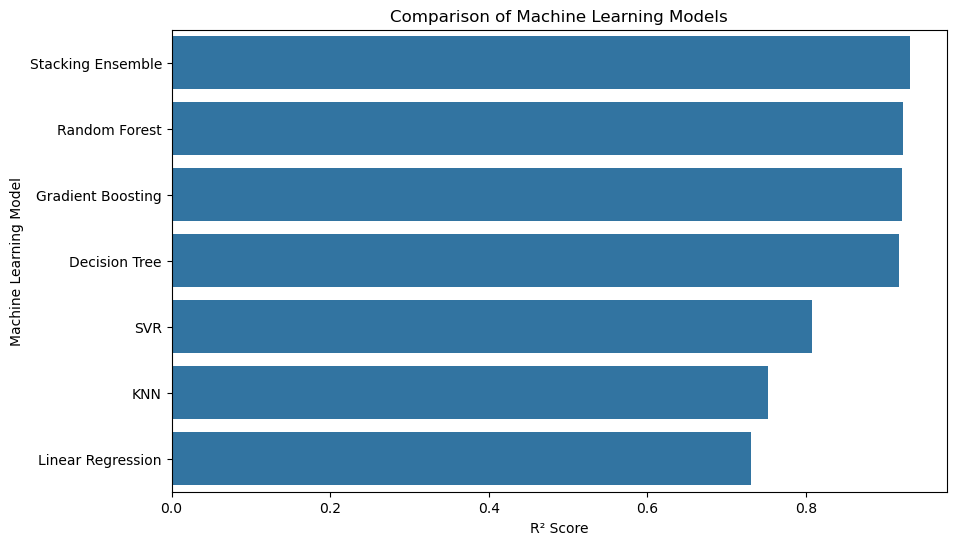

In [22]:
# ============================================================
# STEP 18: MODEL COMPARISON VISUALIZATION
# ============================================================

plt.figure(figsize=(10,6))


sns.barplot(

    data=results_df,

    x="R2 Score",

    y="Model"
)


plt.title(
    "Comparison of Machine Learning Models"
)


plt.xlabel(
    "R² Score"
)


plt.ylabel(
    "Machine Learning Model"
)


plt.show()

In [23]:
# ============================================================
# STEP 19: BEST MODEL SELECTION
# ============================================================

# The model with the highest R² is selected.

best_model_name = results_df.iloc[0]["Model"]


# Retrieve the trained model
best_model = trained_models[
    best_model_name
]


print(
    "BEST MODEL:",
    best_model_name
)

BEST MODEL: Stacking Ensemble


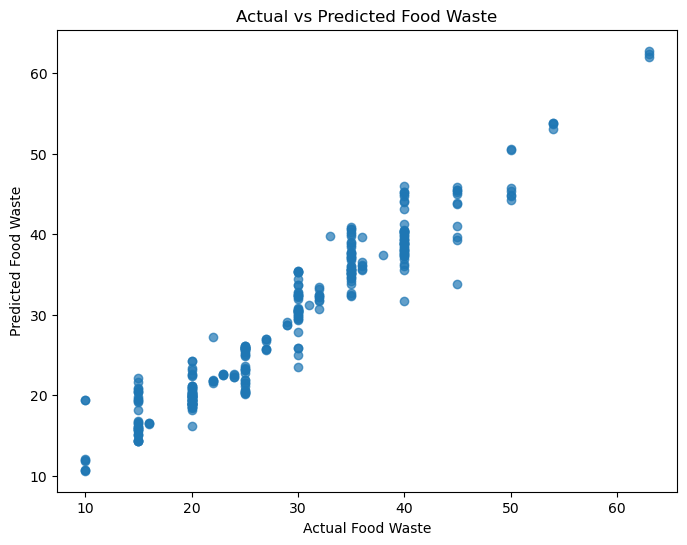

In [24]:
# ============================================================
# STEP 20: ACTUAL VS PREDICTED
# ============================================================

# Generate predictions using best model

best_predictions = best_model.predict(
    X_test
)


# Plot actual vs predicted values

plt.figure(figsize=(8,6))


plt.scatter(

    y_test,

    best_predictions,

    alpha=0.7
)


plt.xlabel(
    "Actual Food Waste"
)


plt.ylabel(
    "Predicted Food Waste"
)


plt.title(
    "Actual vs Predicted Food Waste"
)


plt.show()

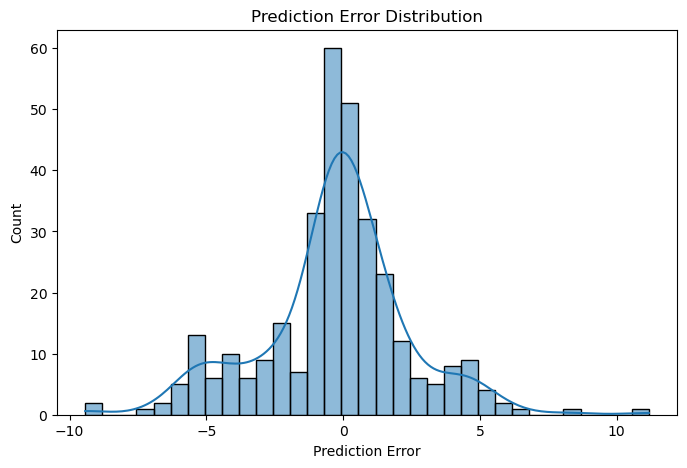

In [25]:
# ============================================================
# STEP 21: ERROR ANALYSIS
# ============================================================

# Calculate prediction errors

errors = (
    y_test -
    best_predictions
)


# Plot error distribution

plt.figure(figsize=(8,5))


sns.histplot(

    errors,

    kde=True
)


plt.xlabel(
    "Prediction Error"
)


plt.title(
    "Prediction Error Distribution"
)


plt.show()

In [26]:
# ============================================================
# STEP 22: FEATURE IMPORTANCE
# ============================================================

# Tree-based models provide feature importance.

tree_models = [

    "Decision Tree",

    "Random Forest",

    "Gradient Boosting"
]


if best_model_name in tree_models:


    # Extract trained ML model
    model = best_model.named_steps[
        "model"
    ]


    # Get encoded feature names
    feature_names = (
        best_model
        .named_steps["preprocessor"]
        .get_feature_names_out()
    )


    # Get feature importance
    importance = (
        model.feature_importances_
    )


    # Create DataFrame
    importance_df = pd.DataFrame({

        "Feature":
            feature_names,

        "Importance":
            importance
    })


    # Sort by importance
    importance_df = (
        importance_df
        .sort_values(
            by="Importance",
            ascending=False
        )
    )


    # Display top features
    display(
        importance_df.head(15)
    )

In [27]:
# ============================================================
# FEATURE IMPORTANCE VISUALIZATION
# ============================================================

if best_model_name in tree_models:


    top_features = (
        importance_df.head(15)
    )


    plt.figure(
        figsize=(10,7)
    )


    sns.barplot(

        data=top_features,

        x="Importance",

        y="Feature"
    )


    plt.title(
        "Top Features Influencing Food Waste"
    )


    plt.show()

In [29]:
# ============================================================
# STEP 23: SHAP EXPLAINABLE AI
# ============================================================

if best_model_name in tree_models:


    # Extract preprocessing pipeline
    fitted_preprocessor = (
        best_model
        .named_steps["preprocessor"]
    )


    # Transform test data
    X_test_processed = (
        fitted_preprocessor
        .transform(X_test)
    )


    # Extract trained tree model
    tree_model = (
        best_model
        .named_steps["model"]
    )


    # Get feature names
    feature_names = (
        fitted_preprocessor
        .get_feature_names_out()
    )


    # Create SHAP explainer
    explainer = shap.TreeExplainer(
        tree_model
    )


    # Calculate SHAP values
    shap_values = (
        explainer.shap_values(
            X_test_processed
        )
    )


    # Display SHAP summary
    shap.summary_plot(

        shap_values,

        X_test_processed,

        feature_names=feature_names
    )

In [42]:
# ============================================================
# STEP 24: NEW FOOD EVENT
# ============================================================

new_event = pd.DataFrame({

    # Type of food
    "Type of Food": [
        "Meat"
    ],


    # Number of guests
    "Number of Guests": [
        350
    ],


    # Type of event
    "Event Type": [
        "Wedding"
    ],


    # Quantity of food prepared
    "Quantity of Food": [
        500
    ],


    # Storage condition
    "Storage Conditions": [
        "Refrigerated"
    ],


    # Purchase history
    "Purchase History": [
        "Frequent"
    ],


    # Season
    "Seasonality": [
        "Summer"
    ],


    # Preparation method
    "Preparation Method": [
        "Buffet"
    ],


    # Location
    "Geographical Location": [
        "Urban"
    ],


    # Pricing category
    "Pricing": [
        "High"
    ],


    # Engineered feature
    "Food_Per_Guest": [
        500 / 350
    ],


    # Guest category
    "Guest_Category": [
        "Large"
    ],


    # Quantity category
    "Quantity_Category": [
        "High"
    ]
})


display(new_event)

,Type of Food,Number of Guests,Event Type,Quantity of Food,Storage Conditions,Purchase History,Seasonality,Preparation Method,Geographical Location,Pricing,Food_Per_Guest,Guest_Category,Quantity_Category
0,Meat,350,Wedding,500,Refrigerated,Frequent,Summer,Buffet,Urban,High,1.428571,Large,High


In [50]:

   # ============================================================
# STEP 25: PREDICT FOOD WASTE FOR A NEW EVENT
# ============================================================

# Create a new event
new_event = pd.DataFrame({

    "Type of Food": ["Meat"],
    "Number of Guests": [350],
    "Event Type": ["Wedding"],
    "Quantity of Food": [500],
    "Storage Conditions": ["Refrigerated"],
    "Purchase History": ["Frequent"],
    "Seasonality": ["Summer"],
    "Preparation Method": ["Buffet"],
    "Geographical Location": ["Urban"],
    "Pricing": ["High"],

    # Engineered features
    "Food_Per_Guest": [500 / 350],
    "Guest_Category": ["Large"],
    "Quantity_Category": ["High"]
})


# Use the best trained model to predict food waste
prediction = best_model.predict(new_event)[0]

# Convert prediction to a normal number
prediction = float(prediction)

print("Predicted Food Waste:",
      round(prediction, 2))

Predicted Food Waste: 39.53


In [51]:

# ============================================================
# STEP 26: UNCERTAINTY ESTIMATION
# ============================================================

# Predict the test dataset
best_predictions = best_model.predict(X_test)

# Calculate prediction errors
residuals = y_test - best_predictions

# Standard deviation of prediction errors
error_std = np.std(residuals)

# 95% prediction interval
lower_bound = max(
    0,
    prediction - (1.96 * error_std)
)

upper_bound = (
    prediction + (1.96 * error_std)
)

print("=" * 50)
print("UNCERTAINTY ESTIMATION")
print("=" * 50)

print("Predicted Food Waste:",
      round(prediction, 2))

print("Lower Bound:",
      round(lower_bound, 2))

print("Upper Bound:",
      round(upper_bound, 2))

print(
    "\n95% Prediction Interval:",
    round(lower_bound, 2),
    "to",
    round(upper_bound, 2)
)

 

UNCERTAINTY ESTIMATION
Predicted Food Waste: 39.53
Lower Bound: 34.21
Upper Bound: 44.86

95% Prediction Interval: 34.21 to 44.86


In [52]:
# ============================================================
# STEP 27: RECOMMENDED PREPARATION QUANTITY
# ============================================================

def optimize_preparation(
    current_quantity,
    predicted_waste
):

    # Reduce part of the predicted waste
    safety_factor = 0.50

    # Calculate recommended quantity
    recommended_quantity = (
        current_quantity
        - predicted_waste * safety_factor
    )

    # Quantity cannot be negative
    recommended_quantity = max(
        recommended_quantity,
        0
    )

    return round(
        recommended_quantity,
        2
    )


# Current quantity of food
current_quantity = 500


# Calculate recommended quantity
recommended_quantity = optimize_preparation(
    current_quantity,
    prediction
)


print("=" * 50)
print("PREPARATION OPTIMIZATION")
print("=" * 50)

print(
    "Current Preparation Quantity:",
    current_quantity
)

print(
    "Predicted Food Waste:",
    round(prediction, 2)
)

print(
    "Recommended Preparation Quantity:",
    recommended_quantity
)


      

   

PREPARATION OPTIMIZATION
Current Preparation Quantity: 500
Predicted Food Waste: 39.53
Recommended Preparation Quantity: 480.23


In [49]:
# ============================================================
# STEP 28: GENERATE FOOD-WASTE ACTION
# ============================================================

waste_percentage, recommendations = (

    generate_recommendation(

        prediction,

        500,

        350
    )
)


print(
    "Estimated Waste Percentage:",
    round(waste_percentage,2),
    "%"
)


print("\nRecommended Actions:")


for action in recommendations:

    print(
        "•",
        action
    )

Estimated Waste Percentage: 7.91 %

Recommended Actions:
• Current preparation quantity is efficient.
• Continue monitoring food waste.
• Use batch-wise food preparation for large events.


In [53]:
# ============================================================
# STEP 29: RECOMMENDED PREPARATION QUANTITY
# ============================================================

def optimize_preparation(

    current_quantity,

    predicted_waste
):


    # Only part of predicted waste is removed
    # to keep a safety margin.

    safety_factor = 0.50


    # Calculate recommended quantity

    recommended_quantity = (

        current_quantity -

        predicted_waste *
        safety_factor
    )


    # Quantity cannot be negative

    recommended_quantity = max(

        recommended_quantity,

        0
    )


    return round(
        recommended_quantity,
        2
    )


recommended_quantity = (

    optimize_preparation(

        500,

        prediction
    )
)


print(
    "Current Preparation Quantity:",
    500
)


print(
    "Predicted Food Waste:",
    round(prediction,2)
)


print(
    "Recommended Preparation Quantity:",
    recommended_quantity
)

Current Preparation Quantity: 500
Predicted Food Waste: 39.53
Recommended Preparation Quantity: 480.23


In [54]:

# ============================================================
# STEP 30: WASTE REDUCTION EVALUATION
# ============================================================

# ------------------------------------------------------------
# IMPORTANT:
# Make sure the prediction exists before continuing.
# If it does not exist, create it again.
# ------------------------------------------------------------

if "prediction" not in globals():

    # Create the new event again
    new_event = pd.DataFrame({

        "Type of Food": ["Meat"],
        "Number of Guests": [350],
        "Event Type": ["Wedding"],
        "Quantity of Food": [500],
        "Storage Conditions": ["Refrigerated"],
        "Purchase History": ["Frequent"],
        "Seasonality": ["Summer"],
        "Preparation Method": ["Buffet"],
        "Geographical Location": ["Urban"],
        "Pricing": ["High"],

        # Engineered features
        "Food_Per_Guest": [500 / 350],
        "Guest_Category": ["Large"],
        "Quantity_Category": ["High"]
    })

    # Generate prediction
    prediction = best_model.predict(new_event)[0]

    # Convert to normal number
    prediction = float(prediction)


# ------------------------------------------------------------
# WHAT-IF WASTE REDUCTION
# ------------------------------------------------------------

# Assume an intervention could reduce waste by 30%.
# This is a simulation, NOT an actual measured result.

reduction_factor = 0.30


# Calculate optimized waste
optimized_waste = (
    prediction *
    (1 - reduction_factor)
)


# Calculate amount of waste saved
waste_saved = (
    prediction -
    optimized_waste
)


# Calculate percentage reduction
reduction_percentage = (
    waste_saved /
    prediction
) * 100


# ------------------------------------------------------------
# DISPLAY RESULTS
# ------------------------------------------------------------

print("=" * 55)
print("WASTE REDUCTION EVALUATION")
print("=" * 55)

print(
    "Predicted Current Waste:",
    round(prediction, 2)
)

print(
    "Optimized Waste:",
    round(optimized_waste, 2)
)

print(
    "Potential Waste Saved:",
    round(waste_saved, 2)
)

print(
    "Potential Waste Reduction:",
    round(reduction_percentage, 2),
    "%"
)

print("=" * 55)

WASTE REDUCTION EVALUATION
Predicted Current Waste: 39.53
Optimized Waste: 27.67
Potential Waste Saved: 11.86
Potential Waste Reduction: 30.0 %


In [55]:

 # ============================================================
# STEP 31: COST-SAVING EVALUATION
# ============================================================

# ------------------------------------------------------------
# STEP 1: Make sure prediction exists
# ------------------------------------------------------------

if "prediction" not in globals():

    # Create a new event for prediction
    new_event = pd.DataFrame({

        "Type of Food": ["Meat"],

        "Number of Guests": [350],

        "Event Type": ["Wedding"],

        "Quantity of Food": [500],

        "Storage Conditions": ["Refrigerated"],

        "Purchase History": ["Frequent"],

        "Seasonality": ["Summer"],

        "Preparation Method": ["Buffet"],

        "Geographical Location": ["Urban"],

        "Pricing": ["High"],

        # Feature engineering
        "Food_Per_Guest": [500 / 350],

        "Guest_Category": ["Large"],

        "Quantity_Category": ["High"]
    })


    # Predict food waste
    prediction = best_model.predict(
        new_event
    )[0]


    # Convert to normal number
    prediction = float(prediction)


# ------------------------------------------------------------
# STEP 2: Calculate waste reduction
# ------------------------------------------------------------

# Assume 30% reduction for a WHAT-IF simulation.
# This is not an actual measured result.

reduction_factor = 0.30


# Calculate optimized waste
optimized_waste = (
    prediction *
    (1 - reduction_factor)
)


# Calculate amount of waste saved
waste_saved = (
    prediction -
    optimized_waste
)


# ------------------------------------------------------------
# STEP 3: Calculate cost saving
# ------------------------------------------------------------

# Estimated cost of one unit of wasted food.
# Change this according to your project data.

cost_per_unit = 120


# Calculate potential cost saving
potential_cost_saving = (
    waste_saved *
    cost_per_unit
)


# ------------------------------------------------------------
# STEP 4: Display results
# ------------------------------------------------------------

print("=" * 60)

print("       COST-SAVING EVALUATION")

print("=" * 60)

print(
    "Predicted Food Waste:",
    round(prediction, 2)
)

print(
    "Optimized Food Waste:",
    round(optimized_waste, 2)
)

print(
    "Food Waste Saved:",
    round(waste_saved, 2)
)

print(
    "Waste Reduction:",
    round(
        reduction_factor * 100,
        2
    ),
    "%"
)

print(
    "Cost per Unit: ₹",
    cost_per_unit
)

print(
    "Potential Cost Saving: ₹",
    round(
        potential_cost_saving,
        2
    )
)

print("=" * 60)

       COST-SAVING EVALUATION
Predicted Food Waste: 39.53
Optimized Food Waste: 27.67
Food Waste Saved: 11.86
Waste Reduction: 30.0 %
Cost per Unit: ₹ 120
Potential Cost Saving: ₹ 1423.2


In [56]:
# ============================================================
# STEP 32: FINAL AI FOOD-WASTE SYSTEM OUTPUT
# ============================================================

# ------------------------------------------------------------
# STEP 1: Make sure prediction exists
# ------------------------------------------------------------

if "prediction" not in globals():

    # Create a sample new event
    new_event = pd.DataFrame({

        "Type of Food": ["Meat"],

        "Number of Guests": [350],

        "Event Type": ["Wedding"],

        "Quantity of Food": [500],

        "Storage Conditions": ["Refrigerated"],

        "Purchase History": ["Frequent"],

        "Seasonality": ["Summer"],

        "Preparation Method": ["Buffet"],

        "Geographical Location": ["Urban"],

        "Pricing": ["High"],

        # Engineered features
        "Food_Per_Guest": [500 / 350],

        "Guest_Category": ["Large"],

        "Quantity_Category": ["High"]
    })


    # Predict food waste
    prediction = best_model.predict(
        new_event
    )[0]


    # Convert prediction to normal number
    prediction = float(prediction)


# ------------------------------------------------------------
# STEP 2: Calculate waste reduction
# ------------------------------------------------------------

# What-if assumption:
# 30% reduction in food waste

reduction_factor = 0.30


# Calculate optimized waste
optimized_waste = (
    prediction *
    (1 - reduction_factor)
)


# Calculate food waste saved
waste_saved = (
    prediction -
    optimized_waste
)


# ------------------------------------------------------------
# STEP 3: Calculate recommended preparation quantity
# ------------------------------------------------------------

current_quantity = 500

safety_factor = 0.50


recommended_quantity = (
    current_quantity -
    prediction * safety_factor
)


# Make sure quantity is not negative
recommended_quantity = max(
    recommended_quantity,
    0
)


# ------------------------------------------------------------
# STEP 4: Calculate cost saving
# ------------------------------------------------------------

# Assumed cost per unit of wasted food
cost_per_unit = 120


potential_cost_saving = (
    waste_saved *
    cost_per_unit
)


# ------------------------------------------------------------
# STEP 5: Display FINAL RESULT
# ------------------------------------------------------------

print()
print("=" * 65)

print("          AI FOOD-WASTE PREDICTION SYSTEM")

print("=" * 65)


# Best model
print(
    "\nBest Model Selected:",
    best_model_name
)


# Predicted food waste
print(
    "Predicted Food Waste:",
    round(prediction, 2)
)


# Uncertainty if available
if "lower_bound" in globals() and "upper_bound" in globals():

    print(
        "Prediction Range:",
        round(lower_bound, 2),
        "to",
        round(upper_bound, 2)
    )


# Current preparation
print(
    "Current Preparation Quantity:",
    current_quantity
)


# Recommended preparation
print(
    "Recommended Preparation Quantity:",
    round(
        recommended_quantity,
        2
    )
)


# Waste saved
print(
    "Potential Food Waste Saved:",
    round(
        waste_saved,
        2
    )
)


# Waste reduction
print(
    "Potential Waste Reduction:",
    round(
        reduction_factor * 100,
        2
    ),
    "%"
)


# Cost saving
print(
    "Potential Cost Saving: ₹",
    round(
        potential_cost_saving,
        2
    )
)


# ------------------------------------------------------------
# STEP 6: Recommended Actions
# ------------------------------------------------------------

print("\nRecommended Actions:")

if prediction / current_quantity * 100 > 20:

    print("• Reduce food preparation quantity.")
    print("• Prepare food in smaller batches.")
    print("• Improve inventory planning.")
    print("• Monitor leftovers during the event.")

elif prediction / current_quantity * 100 > 10:

    print("• Slightly reduce preparation quantity.")
    print("• Monitor buffet refill frequency.")

else:

    print("• Current preparation quantity is efficient.")
    print("• Continue monitoring food waste.")


print("=" * 65)






          AI FOOD-WASTE PREDICTION SYSTEM

Best Model Selected: Stacking Ensemble
Predicted Food Waste: 39.53
Prediction Range: 34.21 to 44.86
Current Preparation Quantity: 500
Recommended Preparation Quantity: 480.23
Potential Food Waste Saved: 11.86
Potential Waste Reduction: 30.0 %
Potential Cost Saving: ₹ 1423.2

Recommended Actions:
• Current preparation quantity is efficient.
• Continue monitoring food waste.
